# DSS: Dự đoán rủi ro giao trễ & rủi ro đánh giá thấp

**Đề tài:** E-commerce DW & DSS — dữ liệu Olist, Brazil 2016–2018

> Notebook **chỉ đọc** kho dữ liệu: không ghi `dw.model_metrics`, `dw.order_risk_score` hay file `models/*.pkl`.
> Muốn train lại thật thì chạy DAG `dss_batch` hoặc `POST /risk/retrain`.

| # | Nội dung |
|---|---|
| 1 | Bài toán và thời điểm ra quyết định |
| 2 | Đọc dữ liệu từ kho (`fact_order_fulfillment`) |
| 3 | Khám phá dữ liệu: giao trễ ảnh hưởng tới đánh giá |
| 4 | Đặc trưng và chống leakage |
| 5 | Chia dữ liệu theo thời gian |
| 6 | Huấn luyện HGB vs LogReg |
| 7 | Ngưỡng quyết định theo chi phí & mức rủi ro |
| 8 | Đường Precision–Recall |
| 9 | Đặc trưng quan trọng |
| 10 | Thí nghiệm: chấm điểm sớm hơn & drift |
| 11 | What-if |
| 12 | Kết luận |

## 1. Bài toán và thời điểm ra quyết định

Vòng đời một đơn: **Mua → Duyệt → Bàn giao vận chuyển → Giao tới khách → Khách viết review**

| Mô hình | Chấm điểm lúc | Nhãn | Hành động khi rủi ro cao |
|---|---|---|---|
| **Rủi ro giao trễ** (`late_delivery`) | Đơn vừa bàn giao cho đơn vị vận chuyển | `is_late`: giao sau ngày hẹn | Liên hệ người bán / hãng vận chuyển, báo trước khách ngày giao mới |
| **Rủi ro đánh giá thấp** (`low_review`) | Đơn vừa giao tới khách, trước khi khách review | `is_low_review`: ≤ 2 sao | Gửi voucher, gọi hỏi thăm trước khi khách đánh giá |

Mỗi mô hình **chỉ được dùng thông tin đã biết tại thời điểm chấm điểm** — nếu không sẽ bị *leakage* (mô hình "nhìn
trước tương lai", điểm cao trên giấy nhưng vô dụng khi chạy thật).

### Cài đặt: kết nối kho dữ liệu (Postgres trong Docker, cổng 5433)

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebook nằm ở dss/notebooks/ -> thêm dss/ vào sys.path để import module của project
DSS_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ROOT = DSS_DIR.parent
sys.path.insert(0, str(DSS_DIR))

# Lấy tài khoản DB từ infra/.env.local (giống docker compose)
env = dict(line.split("=", 1) for line in (ROOT / "infra" / ".env.local").read_text().splitlines()
           if "=" in line and not line.lstrip().startswith("#"))
os.environ.update(DW_DB_HOST="localhost", DW_DB_PORT="5433", DW_DB_USER=env["POSTGRES_USER"],
                  DW_DB_PASSWORD=env["POSTGRES_PASSWORD"], DW_DB_NAME=env["POSTGRES_DB"])

from risk.features import CATEGORICAL, SPECS, WHAT_IF_FIELDS, derive, labeled_mask, load_orders
from risk import train as T

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Các mô hình:", list(SPECS))

Các mô hình: ['late_delivery', 'low_review']


## 2. Đọc dữ liệu từ kho

`load_orders()` đọc `dw.fact_order_fulfillment` — bảng *accumulating snapshot*, **1 dòng / đơn** — join với các
dimension (bang khách, bang người bán, ngành hàng, loại thanh toán), rồi `derive()` tính thêm đặc trưng dẫn xuất.

In [2]:
orders = load_orders()
print(f"{len(orders):,} đơn, {orders.shape[1]} cột")
orders.head(3).T

98,666 đơn, 32 cột


,0,1,2
order_id,00010242fe8c5a6d1ba2dd792cb16214,00018f77f2f0320c557190d7a144bdd3,000229ec398224ef6ca0657da4fc703e
order_status,delivered,delivered,delivered
purchase_ts,2017-09-13 08:59:02,2017-04-26 10:53:06,2018-01-14 14:33:31
carrier_ts,2017-09-19 18:34:16,2017-05-04 14:35:00,2018-01-16 12:36:48
delivered_ts,2017-09-20 23:43:48,2017-05-12 16:04:24,2018-01-22 13:19:16
customer_state,RJ,SP,MG
seller_state,SP,SP,MG
category,cool_stuff,pet_shop,furniture_decor
payment_type,credit_card,credit_card,credit_card
purchase_month,9.000,4.000,1.000


In [3]:
delivered = orders[orders["delivered_ts"].notna()]
not_delivered = orders[orders["delivered_ts"].isna()]

def label_stats(df):
    # Tỷ lệ chỉ tính trên các đơn đã biết kết quả: is_late = NULL khi chưa giao, is_low_review = NULL khi chưa có review
    late, low = df["is_late"].dropna().astype(float), df["is_low_review"].dropna().astype(float)
    return {"Số đơn": len(df),
            "Đã biết trễ/không": len(late), "Tỷ lệ giao trễ": late.mean() if len(late) else np.nan,
            "Đã có review": len(low), "Tỷ lệ review ≤ 2 sao": low.mean() if len(low) else np.nan}

summary = pd.DataFrame({"Tất cả đơn": label_stats(orders), "Đã giao": label_stats(delivered),
                        "Chưa giao (vận chuyển, huỷ…)": label_stats(not_delivered)}).T
summary.style.format({"Số đơn": "{:,.0f}", "Đã biết trễ/không": "{:,.0f}", "Đã có review": "{:,.0f}",
                      "Tỷ lệ giao trễ": "{:.1%}", "Tỷ lệ review ≤ 2 sao": "{:.1%}"}, na_rep="— (chưa giao)")

,Số đơn,Đã biết trễ/không,Tỷ lệ giao trễ,Đã có review,Tỷ lệ review ≤ 2 sao
Tất cả đơn,"98,666","96,476",6.8%,"97,917",14.1%
Đã giao,"96,476","96,476",6.8%,"95,830",12.8%
"Chưa giao (vận chuyển, huỷ…)","2,190",0,— (chưa giao),"2,087",77.1%


- **Đã biết trễ/không** = số đơn đã giao nên biết chắc trễ hay không (không phải số đơn trễ). Đơn chưa giao chưa có
  ngày giao thật để so với ngày hẹn (`is_late` = NULL), nên **tỷ lệ giao trễ chỉ tính trên đơn đã giao** — dòng
  "Tất cả đơn" và "Đã giao" vì vậy có cùng tỷ lệ trễ.
- **Đã có review** = số đơn khách đã viết review. Tỷ lệ review thấp tính trên mọi đơn có review: đơn chưa giao mà khách
  vẫn review (thường do chờ quá lâu hoặc bị huỷ) có tỷ lệ ≤ 2 sao rất cao → kéo tỷ lệ chung lên so với đơn đã giao.
- Mô hình `low_review` chỉ dùng **đơn đã giao** (chấm điểm lúc vừa giao tới khách), nên các đơn chưa giao không vào tập train.
- Hai nhãn đều **lệch** (ít trường hợp dương) → không đánh giá bằng accuracy (đoán "không trễ" cho mọi đơn đã đúng ~93%).

## 3. Khám phá dữ liệu

### 3.1 Giao trễ kéo điểm đánh giá xuống rất mạnh
Đây là giả thuyết nối hai mô hình: nếu dự đoán và xử lý được đơn trễ thì giảm được đánh giá thấp.

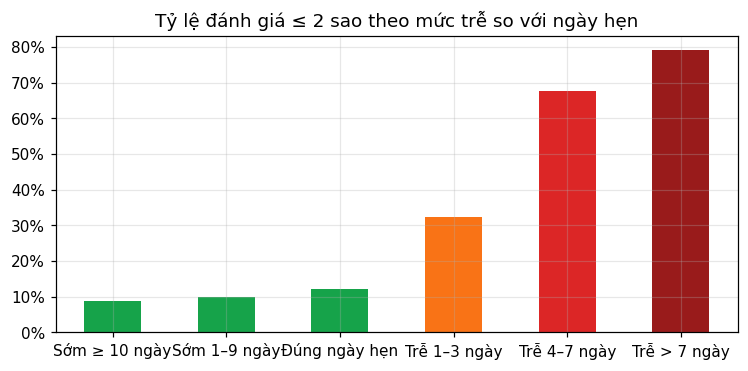

,Số đơn,Tỷ lệ ≤ 2 sao
Mức trễ,,
Sớm ≥ 10 ngày,61528,0.089
Sớm 1–9 ngày,26640,0.099
Đúng ngày hẹn,1280,0.123
Trễ 1–3 ngày,1852,0.322
Trễ 4–7 ngày,1748,0.676
Trễ > 7 ngày,2782,0.792


In [4]:
bins = [-np.inf, -10, -1, 0, 3, 7, np.inf]
labels = ["Sớm ≥ 10 ngày", "Sớm 1–9 ngày", "Đúng ngày hẹn", "Trễ 1–3 ngày", "Trễ 4–7 ngày", "Trễ > 7 ngày"]
d = delivered[delivered["is_low_review"].notna()].copy()
d["Mức trễ"] = pd.cut(d["delay_days"].round(), bins=bins, labels=labels, right=True)
by_delay = d.groupby("Mức trễ", observed=True).agg(**{
    "Số đơn": ("order_id", "size"),
    "Tỷ lệ ≤ 2 sao": ("is_low_review", lambda s: s.astype(float).mean()),
})
ax = by_delay["Tỷ lệ ≤ 2 sao"].plot.bar(color=["#16a34a"] * 3 + ["#f97316", "#dc2626", "#991b1b"], figsize=(8, 3.5), rot=0)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(title="Tỷ lệ đánh giá ≤ 2 sao theo mức trễ so với ngày hẹn", xlabel="", ylabel="")
plt.show()
by_delay

Đơn giao sớm chỉ ~9% bị đánh giá thấp; trễ hơn 7 ngày thì gần **80%**.

### 3.2 Tỷ lệ trễ biến động rất mạnh theo thời gian

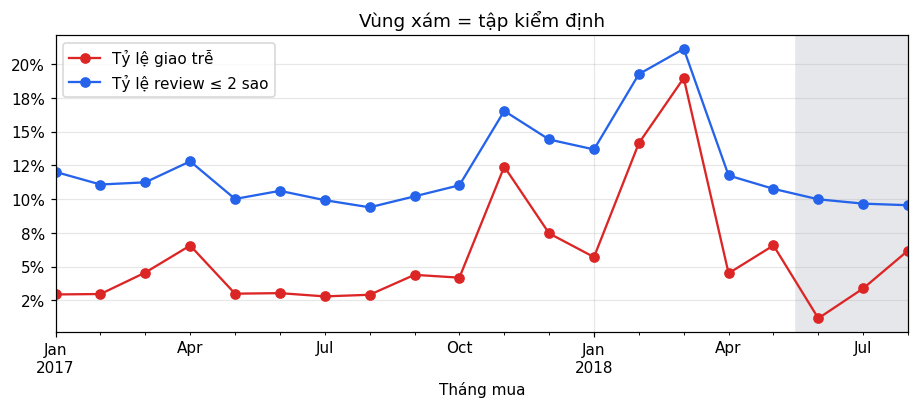

In [5]:
monthly = (delivered.assign(month=delivered["purchase_ts"].dt.to_period("M"))
           .query("'2017-01' <= month <= '2018-08'")
           .groupby("month")[["is_late", "is_low_review"]].agg(lambda s: s.astype(float).mean()))
ax = monthly.plot(marker="o", figsize=(10, 3.5), color=["#dc2626", "#2563eb"])
ax.axvspan(pd.Period("2018-06", "M").ordinal - 0.5, pd.Period("2018-08", "M").ordinal + 0.5, color="#e5e7eb")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(["Tỷ lệ giao trễ", "Tỷ lệ review ≤ 2 sao"]); ax.set(xlabel="Tháng mua", title="Vùng xám = tập kiểm định")
plt.show()

- Đỉnh 11/2017 (Black Friday) và 02–03/2018 (trễ tới **19%**); tập kiểm định 06–08/2018 chỉ ~3,6%.
- Hai đường đi cùng chiều → tháng nào giao trễ nhiều, tháng đó đánh giá thấp nhiều.
- Biến động này (*data drift*) sẽ ảnh hưởng cách chọn ngưỡng — xem Mục 10.

## 4. Đặc trưng và chống leakage

Các đặc trưng có ngay lúc đặt hàng dùng chung cho cả hai mô hình; mỗi mô hình thêm phần thông tin chỉ có ở thời điểm
chấm điểm của nó.

In [6]:
from risk.features import BASE_NUMERIC
rows = []
for name, spec in SPECS.items():
    extra = [c for c in spec.numeric if c not in BASE_NUMERIC]
    rows.append({"Mô hình": name, "Nhãn": spec.target, "Số đặc trưng": len(spec.features),
                 "Đặc trưng riêng (biết tại thời điểm chấm điểm)": ", ".join(extra)})
display(pd.DataFrame(rows).set_index("Mô hình"))
print("Dùng chung - số:", ", ".join(BASE_NUMERIC))
print("Dùng chung - phân loại:", ", ".join(CATEGORICAL))

,Nhãn,Số đặc trưng,Đặc trưng riêng (biết tại thời điểm chấm điểm)
Mô hình,,,
late_delivery,is_late,22,"carrier_days, slack_days, handoff_vs_limit_days"
low_review,is_low_review,23,"carrier_days, actual_days, delay_days, late_flag"


Dùng chung - số: distance_km, same_state, estimated_days, shipping_limit_days, approval_hours, purchase_month, purchase_dow, n_items, n_sellers, total_price, total_freight, freight_ratio, total_weight_g, total_volume_cm3, payment_installments
Dùng chung - phân loại: customer_state, seller_state, category, payment_type


Đặc trưng dẫn xuất quan trọng (tính trong `derive()`):

| Đặc trưng | Công thức | Ý nghĩa |
|---|---|---|
| `slack_days` | `estimated_days − carrier_days` | Sau khi bàn giao còn bao nhiêu ngày tới hạn giao |
| `handoff_vs_limit_days` | `carrier_days − shipping_limit_days` | > 0: người bán bàn giao muộn so với hạn |
| `freight_ratio` | `total_freight / total_price` | Phí ship chiếm bao nhiêu phần giá trị đơn |
| `late_flag` | `delay_days > 0` | Đơn đã giao trễ (chỉ mô hình `low_review` được dùng) |

**Không** dùng cho `late_delivery`: `actual_days`, `delay_days` — đó chính là đáp án.

## 5. Chia dữ liệu theo thời gian (không xáo trộn)

Mô phỏng cách dùng thật: học từ quá khứ, dự đoán đơn tương lai.

| Tập | Thời gian mua |
|---|---|
| Train | 01/2017 → 05/2018 (trong đó validation 03 → 05/2018, chỉ để so sánh cách chọn ngưỡng) |
| Kiểm định (test) | 06/2018 → 08/2018 |

In [7]:
def split(spec):
    labeled = orders[labeled_mask(orders, spec)].copy()
    labeled["y"] = labeled[spec.target].astype(bool).astype(int)
    day = labeled["purchase_ts"].dt.date
    train = labeled[(day >= T.TRAIN_START) & (day < T.TEST_START)]
    fit, valid = train[train["purchase_ts"].dt.date < T.VALID_START], train[train["purchase_ts"].dt.date >= T.VALID_START]
    test = labeled[(day >= T.TEST_START) & (day < T.TEST_END)]
    categories = {c: sorted(train[c].dropna().unique()) for c in CATEGORICAL}
    return train, fit, valid, test, categories

splits = {name: split(spec) for name, spec in SPECS.items()}
pd.DataFrame({name: {"Train": len(s[0]), "  - fit": len(s[1]), "  - validation": len(s[2]), "Test": len(s[3]),
                     "Tỷ lệ dương (train)": s[0]["y"].mean(), "Tỷ lệ dương (test)": s[3]["y"].mean()}
              for name, s in splits.items()}).T

,Train,- fit,- validation,Test,Tỷ lệ dương (train),Tỷ lệ dương (test)
late_delivery,77600.000,57050.000,20550.000,18603.000,0.076,0.036
low_review,77041.000,56619.000,20422.000,18520.000,0.135,0.097


## 6. Huấn luyện: HistGradientBoosting vs Logistic Regression

- **Mô hình chính `hgb_v1`** — `HistGradientBoostingClassifier`: xử lý trực tiếp giá trị thiếu và biến phân loại,
  bắt được quan hệ phi tuyến (vd: còn ít ngày *và* xa *và* bang vùng sâu).
- **Baseline `logreg_v1`** — `LogisticRegression` + one-hot + chuẩn hoá: để chứng minh mô hình chính thật sự tốt hơn.

Chỉ số (trên tập test):
- **ROC-AUC**: khả năng xếp đơn rủi ro lên trên đơn an toàn (0,5 = ngẫu nhiên).
- **PR-AUC**: phù hợp nhãn lệch; mức ngẫu nhiên = tỷ lệ dương.
- **Precision / Recall / F1** tại ngưỡng quyết định (Mục 7).
- **Recall top 10%**: nếu chỉ xử lý 10% đơn rủi ro nhất thì bắt được bao nhiêu % sự cố.

In [8]:
%%time
results = {}
for name, spec in SPECS.items():
    train, fit, valid, test, categories = splits[name]
    X = lambda df: T.to_matrix(df, spec, categories)
    threshold = T.decision_threshold(name)
    for version, factory in [(T.PRIMARY_VERSION, T.new_primary), (T.BASELINE_VERSION, lambda: T.new_baseline(spec))]:
        p_valid = factory().fit(X(fit), fit["y"]).predict_proba(X(valid))[:, 1]
        threshold_valid = T.best_f1_threshold(valid["y"].to_numpy(), p_valid)
        model = factory().fit(X(train), train["y"])
        p_test = model.predict_proba(X(test))[:, 1]
        m = T.evaluate(test["y"].to_numpy(), p_test, threshold)
        m["threshold_valid"] = threshold_valid
        m["f1_valid_threshold"] = T.evaluate(test["y"].to_numpy(), p_test, threshold_valid)["f1"]
        results[(name, version)] = {"model": model, "p_test": p_test, **m}

CPU times: user 23.3 s, sys: 9.92 s, total: 33.2 s
Wall time: 6.41 s


In [9]:
cols = ["positive_rate", "roc_auc", "pr_auc", "threshold", "precision", "recall", "f1", "recall_top10"]
metrics = pd.DataFrame({k: {c: v[c] for c in cols} for k, v in results.items()}).T
metrics.index.names = ["Mô hình", "Phiên bản"]
metrics.style.format("{:.3f}").highlight_max(subset=["roc_auc", "pr_auc", "f1"], color="#dcfce7")

- **Giao trễ:** PR-AUC 0,52 ≈ **14 lần** mức ngẫu nhiên (0,036), gần gấp đôi baseline; F1 0,53 so với 0,22.
- **Đánh giá thấp:** bài toán khó hơn (điểm review còn phụ thuộc chất lượng sản phẩm, kỳ vọng của khách — không có
  trong dữ liệu), nhưng HGB vẫn hơn baseline; PR-AUC ≈ 3,3 lần ngẫu nhiên.

## 7. Ngưỡng quyết định theo chi phí & mức rủi ro

Cảnh báo một đơn khi lợi ích kỳ vọng lớn hơn chi phí:

$$p \cdot C_{FN} > (1-p) \cdot C_{FP} \iff p \ge t = \frac{C_{FP}}{C_{FP} + C_{FN}}$$

- $C_{FP}$: chi phí can thiệp không cần thiết; $C_{FN}$: chi phí bỏ sót một sự cố.
- Mức rủi ro: **High** nếu $p \ge t$, **Medium** nếu $t/2 \le p < t$, còn lại **Low**.

In [10]:
pd.DataFrame({name: {"C_FP": c[0], "C_FN": c[1], "Ngưỡng t": T.decision_threshold(name)}
              for name, c in T.DECISION_COSTS.items()}).T

,C_FP,C_FN,Ngưỡng t
late_delivery,1.000,1.000,0.500
low_review,10.000,40.000,0.200


- Giao trễ: gọi người bán ≈ chi phí một đơn trễ không báo trước → t = 0,5.
- Đánh giá thấp: voucher R$10, mất khách R$40 → t = 0,2 (chấp nhận gửi nhầm voucher để giữ khách).

In [11]:
rows = []
for name in SPECS:
    r = results[(name, T.PRIMARY_VERSION)]
    y = splits[name][3]["y"].to_numpy()
    lv = T.risk_level(r["p_test"], r["threshold"])
    for level in ["High", "Medium", "Low"]:
        mask = lv == level
        rows.append({"Mô hình": name, "Mức": level, "Số đơn": mask.sum(), "Tỷ lệ xảy ra thật": y[mask].mean()})
levels = pd.DataFrame(rows).pivot(index="Mức", columns="Mô hình").loc[["High", "Medium", "Low"]]
levels.style.format({c: "{:.1%}" for c in levels.columns if c[0] == "Tỷ lệ xảy ra thật"})

Tỷ lệ xảy ra thật giảm rõ từ High xuống Low (giao trễ: ~75% → ~2%) → Ops có thể tin vào cách xếp mức để ưu tiên xử lý.

## 8. Đường Precision–Recall

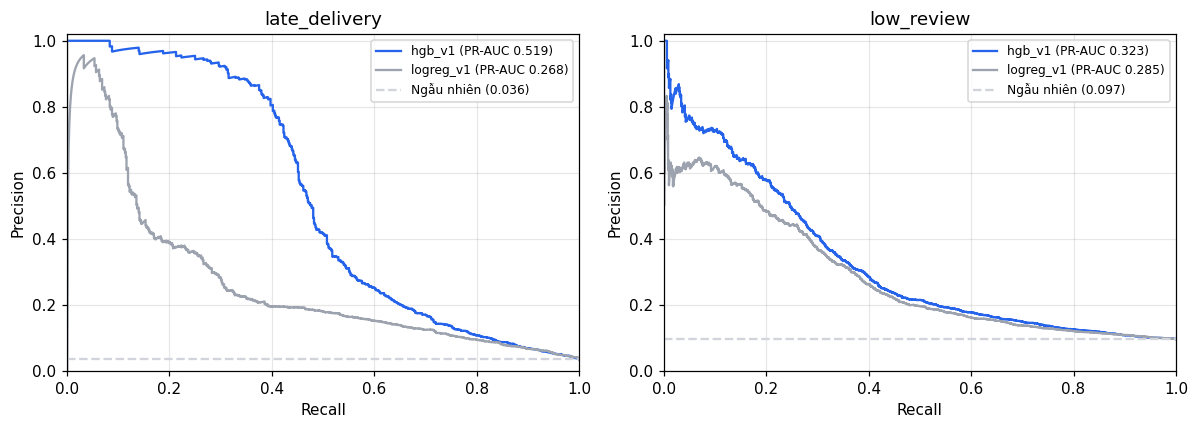

In [12]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, SPECS):
    y = splits[name][3]["y"].to_numpy()
    for version, color in [(T.PRIMARY_VERSION, "#2563eb"), (T.BASELINE_VERSION, "#9ca3af")]:
        r = results[(name, version)]
        prec, rec, _ = precision_recall_curve(y, r["p_test"])
        ax.plot(rec, prec, color=color, label=f"{version} (PR-AUC {r['pr_auc']:.3f})")
    ax.axhline(y.mean(), ls="--", color="#d1d5db", label=f"Ngẫu nhiên ({y.mean():.3f})")
    ax.set(title=name, xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Đường HGB (xanh) nằm trên baseline (xám) ở hầu hết các mức recall. Với giao trễ, precision gần 1 ở vùng recall < 0,2: các đơn này gần như chắc chắn trễ.

## 9. Đặc trưng quan trọng (permutation importance)

Xáo trộn ngẫu nhiên một cột rồi đo PR-AUC giảm bao nhiêu → cột càng quan trọng thì giảm càng nhiều.
Tính trên 6.000 đơn test (giống `train.py`); mất khoảng 1 phút.

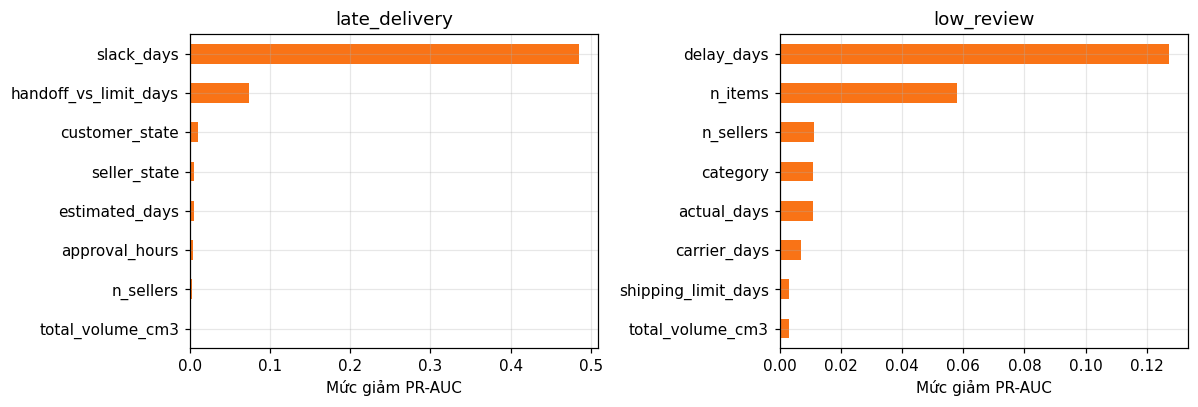

CPU times: user 19.9 s, sys: 8.62 s, total: 28.6 s
Wall time: 5.6 s


In [13]:
%%time
from sklearn.inspection import permutation_importance

importance = {}
for name, spec in SPECS.items():
    _, _, _, test, categories = splits[name]
    sample = test.sample(min(T.IMPORTANCE_SAMPLE, len(test)), random_state=T.RANDOM_STATE)
    imp = permutation_importance(results[(name, T.PRIMARY_VERSION)]["model"], T.to_matrix(sample, spec, categories),
                                 sample["y"], scoring="average_precision", n_repeats=5, random_state=T.RANDOM_STATE)
    importance[name] = pd.Series(imp.importances_mean, index=spec.features).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, s) in zip(axes, importance.items()):
    s.head(8)[::-1].plot.barh(ax=ax, color="#f97316", title=name)
    ax.set_xlabel("Mức giảm PR-AUC")
plt.tight_layout(); plt.show()

- **Giao trễ:** `slack_days` áp đảo — đơn bàn giao sát hạn thì khó kịp; tiếp theo `handoff_vs_limit_days` (người bán
  bàn giao muộn). → Đòn bẩy lớn nhất: **ép người bán bàn giao đúng hạn**.
- **Đánh giá thấp:** `delay_days` đứng đầu (khớp Mục 3.1), sau đó `n_items`, `n_sellers` — đơn nhiều món / nhiều
  người bán dễ giao thiếu hoặc lệch nhau.

## 10. Thí nghiệm bổ sung

### 10.1 Nếu chấm điểm sớm hơn — ngay lúc khách đặt hàng?
Chỉ dùng đặc trưng có lúc đặt hàng (`BASE_NUMERIC` + phân loại), bỏ thông tin bàn giao / giao hàng.

In [14]:
from risk.features import ModelSpec

rows = []
for name, spec in SPECS.items():
    early = ModelSpec(name=name, target=spec.target, numeric=BASE_NUMERIC, description="purchase-time only")
    train, _, _, test, categories = splits[name]
    model = T.new_primary().fit(T.to_matrix(train, early, categories), train["y"])
    m = T.evaluate(test["y"].to_numpy(), model.predict_proba(T.to_matrix(test, early, categories))[:, 1], T.decision_threshold(name))
    full = results[(name, T.PRIMARY_VERSION)]
    rows.append({"Mô hình": name, "ROC-AUC lúc đặt hàng": m["roc_auc"], "PR-AUC lúc đặt hàng": m["pr_auc"],
                 "ROC-AUC thời điểm đã chọn": full["roc_auc"], "PR-AUC thời điểm đã chọn": full["pr_auc"]})
pd.DataFrame(rows).set_index("Mô hình")

,ROC-AUC lúc đặt hàng,PR-AUC lúc đặt hàng,ROC-AUC thời điểm đã chọn,PR-AUC thời điểm đã chọn
Mô hình,,,,
late_delivery,0.693,0.073,0.868,0.519
low_review,0.620,0.186,0.703,0.323


Chấm điểm lúc đặt hàng gần như vô dụng cho giao trễ (PR-AUC gần mức ngẫu nhiên) → lý do chọn chấm điểm **lúc bàn giao vận chuyển**.

### 10.2 Chọn ngưỡng tối đa F1 trên validation — bị data drift làm lệch

In [15]:
pd.DataFrame({name: {"Ngưỡng max-F1 (validation)": results[(name, T.PRIMARY_VERSION)]["threshold_valid"],
                     "F1 test với ngưỡng đó": results[(name, T.PRIMARY_VERSION)]["f1_valid_threshold"],
                     "Ngưỡng theo chi phí": results[(name, T.PRIMARY_VERSION)]["threshold"],
                     "F1 test với ngưỡng chi phí": results[(name, T.PRIMARY_VERSION)]["f1"]}
              for name in SPECS}).T

,Ngưỡng max-F1 (validation),F1 test với ngưỡng đó,Ngưỡng theo chi phí,F1 test với ngưỡng chi phí
late_delivery,0.070,0.207,0.500,0.534
low_review,0.300,0.323,0.200,0.344


Validation (03–05/2018) có tỷ lệ trễ cao bất thường (19% ở 03/2018) nên ngưỡng tối ưu ở đó rất thấp; áp sang test
(3,6% trễ) thì cảnh báo tràn lan, F1 chỉ ~0,21. Ngưỡng nên đặt từ **chi phí nghiệp vụ** và được theo dõi định kỳ.

## 11. What-if: thay đổi một quyết định thì rủi ro còn bao nhiêu?

Ops chọn một đơn đang vận chuyển có rủi ro trễ cao rồi thử các phương án. Logic giống `what_if()` trong `predict.py`:
đổi cột gốc → `derive()` tính lại đặc trưng dẫn xuất → chấm lại.

In [16]:
name, spec = "late_delivery", SPECS["late_delivery"]
train, _, _, test, categories = splits[name]
model = results[(name, T.PRIMARY_VERSION)]["model"]

def score(df):
    return model.predict_proba(T.to_matrix(df, spec, categories))[:, 1]

# Chọn 1 đơn trong tập test bị trễ thật, người bán bàn giao muộn
candidates = test[(test["y"] == 1) & (test["handoff_vs_limit_days"] > 0)]
order = candidates.iloc[[0]]
print("Đơn:", order["order_id"].iloc[0])
order[["estimated_days", "shipping_limit_days", "carrier_days", "slack_days", "handoff_vs_limit_days", "distance_km"]]

Đơn: 00a379dfab816a83741012b71b264098


,estimated_days,shipping_limit_days,carrier_days,slack_days,handoff_vs_limit_days,distance_km
224,5.000,4.010,5.740,-0.740,1.730,15.600


In [17]:
scenarios = {
    "Hiện trạng": {},
    "Người bán bàn giao sớm hơn 3 ngày": {"carrier_days": order["carrier_days"].iloc[0] - 3},
    "Bàn giao đúng hạn": {"carrier_days": order["shipping_limit_days"].iloc[0]},
    "Nới ngày hẹn thêm 5 ngày": {"estimated_days": order["estimated_days"].iloc[0] + 5},
}
rows = []
for label, overrides in scenarios.items():
    changed = derive(order.assign(**overrides))
    p = score(changed)[0]
    rows.append({"Kịch bản": label, "Rủi ro trễ": p, "Mức": T.risk_level(np.array([p]), T.decision_threshold(name))[0]})
pd.DataFrame(rows).set_index("Kịch bản").style.format({"Rủi ro trễ": "{:.1%}"})

,Rủi ro trễ,Mức
Kịch bản,,
Hiện trạng,79.5%,High
Người bán bàn giao sớm hơn 3 ngày,5.5%,Low
Bàn giao đúng hạn,70.4%,High
Nới ngày hẹn thêm 5 ngày,11.8%,Low


- Người bán **bàn giao sớm hơn 3 ngày** kéo rủi ro từ High (~80%) xuống Low (~6%). Chỉ bàn giao **đúng hạn** (sớm
  hơn ~1,7 ngày với đơn này) thì vẫn ở mức High (~70%): đơn hẹn giao quá gần, cần bàn giao sớm hơn cả hạn.
- **Nới ngày hẹn thêm 5 ngày** cũng xuống Low (~12%) nhưng giảm ít hơn, và khách vẫn chờ lâu, chỉ là ít bị coi là "trễ".
- → Hành động ưu tiên: thúc người bán bàn giao, khớp với kết quả feature importance ở Mục 9.

Trên giao diện Ops Console, nút **Simulate action** của mỗi đơn đang vận chuyển (dời ngày hẹn giao thêm N ngày) gọi đúng logic này qua API `POST /risk/{model}/what-if`.

## 12. Kết luận

| | Rủi ro giao trễ | Rủi ro đánh giá thấp |
|---|---|---|
| Thời điểm chấm điểm | Bàn giao vận chuyển | Vừa giao tới khách |
| ROC-AUC / PR-AUC (HGB) | ~0,87 / ~0,52 | ~0,70 / ~0,32 |
| Hơn baseline LogReg | PR-AUC gần gấp đôi | Có, mức vừa phải |
| Đặc trưng quan trọng nhất | `slack_days`, bàn giao muộn | `delay_days`, số món trong đơn |
| Hành động | Ép người bán bàn giao đúng hạn, báo trước khách | Voucher / hỏi thăm trước khi review |

**Hạn chế:** dữ liệu tĩnh tới 2018; không có thông tin hãng vận chuyển, thời tiết, sự kiện; chi phí $C_{FP}, C_{FN}$
là giả định của nhóm; review còn phụ thuộc chất lượng sản phẩm thật.

**Sản phẩm thực tế:** kết quả chấm điểm được ghi vào `dw.order_risk_score` (DAG `dss_batch`) và hiển thị trên Ops Console
(`http://localhost:5173/#/ops`).